# Gradient Descent (User Input)

## **🔸 Imports**

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

## **🔸animate Func**

In [5]:
import matplotlib.animation as animation
from IPython.display import HTML

def animate(x, func, gradfunc, xi, eta, N):
    if gradfunc is None:
        gradfunc = func

    xi_hist = [xi]

    for iteration in range(N):
        xi = GradientDescent(gradfunc, xi, eta, 1)
        xi_hist.append(xi)

    xi_hist = np.array(xi_hist)
    fxi_hist = func(xi_hist)

    fig, ax = plt.subplots(figsize=(8, 6))

    def plot_animate(i):
        ax.clear()

        ax.plot(x, func(x), linewidth=3)
        ax.plot(
            xi_hist[:i+1],
            fxi_hist[:i+1],
            color='black',
            linewidth=4
        )
        ax.plot(
            xi_hist[0],
            fxi_hist[0],
            'r*',
            markersize=15
        )

        ax.set_xlabel('x')
        ax.set_ylabel('f(x)')

    ani = animation.FuncAnimation(
        fig,
        plot_animate,
        frames=len(xi_hist),
        interval=120,
        repeat=False
    )

    plt.close(fig)

    return HTML(ani.to_jshtml())


## **🔸Func F(x)**

In [6]:
x = sp.symbols('x')

print("Enter your function in terms of x:")
print("Example: (x-3)**2 + 3")

expression = input("f(x) = ")

expr = sp.sympify(expression)

func = sp.lambdify(x, expr, modules='numpy')


Enter your function in terms of x:
Example: (x-3)**2 + 3


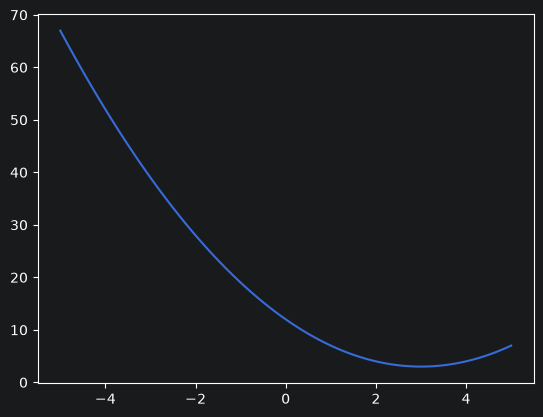

In [7]:
x = np.linspace(-5, 5, 100)

plt.plot(x, func(x))


## **🔸GradFunc F(x)**

In [8]:
def gradfunc(expr):
    x = sp.symbols('x')

    grad_expr = sp.diff(expr, x)

    grad_func = sp.lambdify(x, grad_expr, modules='numpy')

    return grad_func

In [9]:
gradient = gradfunc(expr)

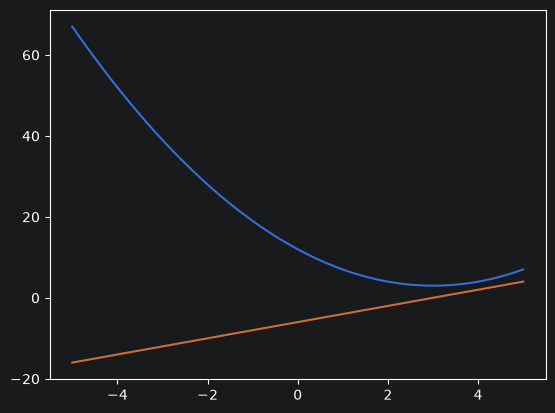

In [10]:
plt.plot(x, func(x), label='Function')
plt.plot(x, gradient(x), label='Gradient')

## **🔸Gradient Descent**

#### Getting the hyperparameters of eta, Xi and Epoch from user

In [11]:
print("Enter Xi:")
xi = float(input("xi = "))
print("Enter eta:")
eta = float(input("eta = "))
print("Enter epoch:")
epoch = int(input("epoch = "))


Enter Xi:
Enter eta:
Enter epoch:


In [12]:
def GradientDescent(gradfunc, xi, eta, N):
    for i in range(N):
        grad = gradfunc(xi)
        xi -= eta*grad
    return xi

In [13]:
GradientDescent(gradient, xi, eta, epoch)

2.9998929564230474

## **🔸Animation Gradient Descent**

In [14]:
x = np.linspace(-5, 5, 100)
animate(x, func, gradient, xi , eta,epoch)